# Exploratory Data Analysis: Dudley Employment Barriers

## Purpose

Explore how economic activity, qualifications, disability,
car availability and deprivation vary across Dudley neighbourhoods.

The analysis addresses the project question:

**What does Dudley’s labour-market profile suggest about the
different support people may need to move into work?**

## Data and scope

This notebook uses `dudley_combined_prepared.csv`, containing
199 geographically compatible LSOAs and 105 columns.

The dataset combines Census 2021 measures with historical
IoD2019 deprivation measures. The 199 shared areas were verified
against the official ONS boundary lookup.

Four Census areas without matching deprivation codes were excluded.
The combined dataset therefore does not cover all 203 Census areas
in Dudley.

## Planned exploration

- Produce descriptive statistics for selected measures.
- Examine distributions and differences between areas.
- Investigate unusual values without automatically removing them.
- Explore relationships to inform later hypothesis testing.
- Record findings and limitations alongside the analysis.

## Ethical considerations and interpretation

These are area-level statistics. Patterns between neighbourhoods
do not establish individual circumstances or causes of unemployment.

Disability does not imply inability or unwillingness to work.
Having no qualifications does not mean having no skills.
Having no car does not automatically mean poor transport access.

Economic activity percentages use residents aged 16 and over as
their denominator. The unemployment population share is not an
unemployment rate. Selected inactivity categories do not represent
total economic inactivity.

Car availability percentages describe households, while other
Census percentages describe people. Deprivation measures provide
historical context and should not be presented as current conditions.

Findings will use respectful language and distinguish observed
patterns from possible explanations.

---

# Change working directory

* We are assuming you will store the notebooks in a subfolder, therefore when running the notebook in the editor, you will need to change the working directory

We need to change the working directory from its current folder to its parent folder
* We access the current directory with os.getcwd()

In [1]:
import os
current_dir = os.getcwd()
current_dir

'c:\\Dudley employment barriers\\jupyter_notebooks'

We want to make the parent of the current directory the new current directory
* os.path.dirname() gets the parent directory
* os.chir() defines the new current directory

In [2]:
os.chdir(os.path.dirname(current_dir))
print("You set a new current directory")

You set a new current directory


Confirm the new current directory

In [3]:
current_dir = os.getcwd()
current_dir

'c:\\Dudley employment barriers'

## 1. Load and inspect the prepared dataset

Load `dudley_combined_prepared.csv` and confirm that it contains
the expected 199 LSOAs and 105 columns.

Preview the first few rows to check that the file has loaded correctly.

In [4]:
# Developed with ChatGPT assistance to load and inspect the dataset.

import pandas as pd

# Load the prepared dataset.
data_path = "cleaned_datasets/dudley_combined_prepared.csv"
df = pd.read_csv(data_path)

# Check the dimensions and preview the first five rows.
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

df.head()

Rows: 199
Columns: 105


,Economic_Total_16_Plus,Economically_Active_Excl_FT_Students,Employed_Excl_FT_Students,Unemployed_Excl_FT_Students,Inactive_Student,Inactive_Home_Or_Family,Inactive_Long_Term_Sick_Or_Disabled,Inactive_Other,LSOA_Code,LSOA_Name,...,IoD2019_Indoors_Sub_domain_Rank,IoD2019_Indoors_Sub_domain_Decile,IoD2019_Outdoors_Sub_domain_Score,IoD2019_Outdoors_Sub_domain_Rank,IoD2019_Outdoors_Sub_domain_Decile,IoD2019_Total_population_mid_2015_excluding_prisoners,IoD2019_Dependent_Children_aged_0_15_mid_2015_excluding_prisoners,IoD2019_Population_aged_16_59_mid_2015_excluding_prisoners,IoD2019_Older_population_aged_60_and_over_mid_2015_excluding_prisoners,IoD2019_Working_age_population_18_59_64_for_use_with_Employment_Deprivation_Domain_excluding_prisoners
0,1637,970,888,82,97,164,73,70,E01009763,Dudley 001A,...,14369,5,-0.212,18843,6,1817,458,1073,286,1038
1,1264,759,731,28,35,50,35,31,E01009764,Dudley 001B,...,3121,1,-0.035,15873,5,1380,219,800,361,810
2,1265,748,699,49,35,69,66,28,E01009767,Dudley 001C,...,9455,3,-0.167,18091,6,1519,276,836,407,848
3,1431,701,618,83,78,119,148,59,E01009769,Dudley 001D,...,5299,2,0.532,8066,3,1711,384,944,383,955
4,1214,664,625,39,41,73,69,50,E01009770,Dudley 001E,...,6292,2,-0.275,19903,7,1487,262,817,408,826


### Findings

The prepared dataset loaded successfully with 199 rows and 105 columns,
matching the expected dimensions.

The preview shows LSOA codes and names alongside Census counts and
historical IoD2019 measures.

The dataset covers the 199 geographically compatible LSOAs retained
during preparation, rather than all 203 Census areas in Dudley.

---

## 2. Check the dataset structure

Inspect the column names and data types before selecting measures
for exploration.

Confirm that each LSOA code appears once and check for missing values
or duplicate rows after loading the saved CSV.

In [5]:
# Developed with ChatGPT assistance to inspect the dataset structure.

# Summarise area identifiers, duplicate rows and missing values.
print(f"Unique LSOA codes: {df['LSOA_Code'].nunique()}")
print(f"Missing LSOA codes: {df['LSOA_Code'].isna().sum()}")
print(f"Duplicate LSOA codes: {df['LSOA_Code'].duplicated().sum()}")
print(f"Duplicate rows: {df.duplicated().sum()}")
print(f"Total missing values: {df.isna().sum().sum()}")

# Show every column with its data type and missing-value count.
column_summary = pd.DataFrame({
    "Column": df.columns,
    "Data_Type": df.dtypes.astype(str).to_numpy(),
    "Missing_Values": df.isna().sum().to_numpy()
})

print("\nColumn summary:")
print(column_summary.to_string(index=False))

Unique LSOA codes: 199
Missing LSOA codes: 0
Duplicate LSOA codes: 0
Duplicate rows: 0
Total missing values: 0

Column summary:
                                                                                                Column Data_Type  Missing_Values
                                                                                Economic_Total_16_Plus     int64               0
                                                                  Economically_Active_Excl_FT_Students     int64               0
                                                                             Employed_Excl_FT_Students     int64               0
                                                                           Unemployed_Excl_FT_Students     int64               0
                                                                                      Inactive_Student     int64               0
                                                                               Inactive_Home_Or_Fa

### Findings

The dataset contains 199 unique LSOA codes, with no missing or
duplicate codes. No duplicate rows or missing values were detected
across the 105 columns.

Area codes and names loaded as text. Counts, deprivation ranks and
deciles loaded as integers, while percentages and deprivation scores
loaded as decimal numbers.

No structural issues were identified by these checks. Numeric data
types alone do not confirm that values fall within valid ranges;
selected measures will be examined during exploration.

---

## 3. Descriptive statistics for selected Census measures

Summarise employment, unemployment population share, selected reasons
for economic inactivity, qualifications, disability and car availability.

Calculate the mean, standard deviation, minimum, quartiles and maximum
across the 199 included LSOAs. Check whether any selected percentages
fall outside the valid range of 0 to 100.

Each LSOA receives equal weight in these summaries. The mean therefore
describes the average neighbourhood percentage, not the overall
percentage of Dudley residents or households.

Economic activity measures use residents aged 16 and over as their
denominator. Employment and unemployment counts exclude full-time
students. The unemployment population share is not an unemployment rate.

Car availability measures describe households. The other selected
percentages describe residents aged 16 and over, using their respective
source totals. Deprivation measures will be summarised separately
because they use different scales.

In [6]:
# Developed with ChatGPT assistance to summarise Census measures.

# Select measures relevant to the project question.
census_measures = [
    "Employed_Excl_FT_Students_Pct",
    "Unemployed_Excl_FT_Students_Pct",
    "Inactive_Home_Or_Family_Pct",
    "Inactive_Long_Term_Sick_Or_Disabled_Pct",
    "No_Qualifications_Pct",
    "Level_4_And_Above_Pct",
    "Disabled_16_Plus_Pct",
    "Limited_A_Lot_16_Plus_Pct",
    "No_Car_Van_Households_Pct"
]

# Summarise variation across LSOAs.
census_summary = df[census_measures].describe().T
census_summary = census_summary.rename(columns={
    "count": "Areas",
    "mean": "Mean",
    "std": "Std_Dev",
    "min": "Minimum",
    "25%": "Q1",
    "50%": "Median",
    "75%": "Q3",
    "max": "Maximum"
})

# Count values outside the valid percentage range.
census_summary["Outside_0_100"] = (
    (df[census_measures] < 0) | (df[census_measures] > 100)
).sum()

# Round only the displayed summary, preserving the original data.
print(census_summary.round(2).to_string())

                                         Areas   Mean  Std_Dev  Minimum     Q1  Median     Q3  Maximum  Outside_0_100
Employed_Excl_FT_Students_Pct            199.0  53.87     5.07    41.07  50.54   53.57  56.82    70.26              0
Unemployed_Excl_FT_Students_Pct          199.0   3.15     1.51     0.49   2.06    2.93   3.94    10.40              0
Inactive_Home_Or_Family_Pct              199.0   5.08     2.58     1.29   2.99    4.35   6.74    13.59              0
Inactive_Long_Term_Sick_Or_Disabled_Pct  199.0   4.44     2.49     0.30   2.42    4.07   6.21    11.58              0
No_Qualifications_Pct                    199.0  22.98     5.79    10.19  18.30   23.39  27.37    36.96              0
Level_4_And_Above_Pct                    199.0  24.99     6.85    13.76  19.66   24.04  29.24    49.65              0
Disabled_16_Plus_Pct                     199.0  22.28     3.87    13.17  19.77   22.02  24.88    36.73              0
Limited_A_Lot_16_Plus_Pct                199.0   9.73   

### Findings

All nine selected measures contain values for 199 LSOAs, with no
percentages outside the valid range of 0 to 100.

- Employment excluding full-time students averages 53.87% of residents
  aged 16 and over across neighbourhoods, ranging from 41.07% to 70.26%.
- The unemployment population share averages 3.15%, ranging from 0.49%
  to 10.40%. This is not an unemployment rate.
- Inactivity due to looking after home or family averages 5.08%.
  Inactivity due to long-term sickness or disability averages 4.44%.
  These categories do not represent total economic inactivity.
- The percentage with no qualifications ranges from 10.19% to 36.96%,
  while Level 4 or above qualifications range from 13.76% to 49.65%.
- Disabled residents account for an average neighbourhood share of
  22.28%. Those whose activities are limited a lot account for 9.73%
  of all residents aged 16 and over, not 9.73% of disabled residents.
- Households without a car or van show the greatest spread among
  these measures: 3.23% to 50.58%, with a standard deviation of
  9.20 percentage points.

These results show differences between neighbourhoods but do not
explain their causes. The means give each LSOA equal weight and
should not be presented as overall Dudley percentages.

The higher and lower values will be explored further rather than
automatically treated as errors or removed.

---

## 4. Descriptive statistics for historical deprivation

Summarise the IoD2019 Index of Multiple Deprivation (IMD) score
and selected domain scores covering income, employment, education,
and health and disability.

These measures provide historical context for the Census 2021
patterns. They do not describe current deprivation.

Summarise each measure on its original scale. Scores from different
domains are not directly comparable and should not be averaged
together.

Count the included LSOAs in each national IMD decile. Decile 1
represents the most deprived tenth of English LSOAs, while decile 10
represents the least deprived tenth.

The summaries give each included LSOA equal weight. Decile counts
describe areas, not the number or percentage of residents.

In [7]:
# Developed with ChatGPT assistance to summarise historical deprivation.

# Keep deprivation measures separate from Census percentages.
deprivation_measures = [
    "IoD2019_IMD_Score",
    "IoD2019_Income_Score_rate",
    "IoD2019_Employment_Score_rate",
    "IoD2019_Education_Skills_and_Training_Score",
    "IoD2019_Health_Deprivation_and_Disability_Score"
]

deprivation_summary = df[deprivation_measures].describe().T
deprivation_summary = deprivation_summary.rename(columns={
    "count": "Areas",
    "mean": "Mean",
    "std": "Std_Dev",
    "min": "Minimum",
    "25%": "Q1",
    "50%": "Median",
    "75%": "Q3",
    "max": "Maximum"
})

print("Historical deprivation scores (original scales):")
print(deprivation_summary.round(3).to_string())

# Check decile values before counting areas in each category.
imd_deciles = df["IoD2019_IMD_Decile"]
invalid_deciles = (~imd_deciles.isin(range(1, 11))).sum()

print(f"\nInvalid or missing IMD deciles: {invalid_deciles}")

decile_counts = (
    imd_deciles.value_counts()
    .reindex(range(1, 11), fill_value=0)
    .sort_index()
    .rename_axis("IMD_Decile")
    .rename("Number_of_LSOAs")
)

print("\nIncluded LSOAs by national IMD decile:")
print(decile_counts.to_string())

Historical deprivation scores (original scales):
                                                 Areas    Mean  Std_Dev  Minimum      Q1  Median      Q3  Maximum
IoD2019_IMD_Score                                199.0  22.946   14.400    3.360   9.965  21.239  33.214   63.363
IoD2019_Income_Score_rate                        199.0   0.148    0.094    0.020   0.066   0.133   0.216    0.408
IoD2019_Employment_Score_rate                    199.0   0.117    0.063    0.021   0.062   0.106   0.164    0.297
IoD2019_Education_Skills_and_Training_Score      199.0  27.076   19.260    1.440  10.016  22.556  42.250   92.175
IoD2019_Health_Deprivation_and_Disability_Score  199.0   0.253    0.523   -0.927  -0.150   0.215   0.641    1.722

Invalid or missing IMD deciles: 0

Included LSOAs by national IMD decile:
IMD_Decile
1     20
2     30
3     26
4     21
5     21
6      8
7     16
8     20
9     18
10    19


### Findings

All five selected deprivation measures contain values for 199 LSOAs.
No invalid or missing IMD deciles were detected.

IMD scores range from 3.360 to 63.363, with a median of 21.239,
showing variation in historical deprivation across the included areas.

All ten national IMD deciles are represented:
- 20 LSOAs fall within the most deprived national decile.
- 50 LSOAs fall within the most deprived two deciles, representing
  25.1% of the 199 included areas.
- 19 LSOAs fall within the least deprived national decile.
- Decile 2 contains the largest number of included LSOAs, with 30.

Income deprivation scores range from 0.020 to 0.408, and employment
deprivation scores range from 0.021 to 0.297. These retain their
original rate scales and source-specific definitions; the employment
deprivation measure is not the Census unemployment population share.

Education scores range from 1.440 to 92.175. Health deprivation and
disability scores range from -0.927 to 1.722. Negative values on the
standardised health deprivation scale are not automatically errors.

The domains use different scales, so their score magnitudes should
not be compared directly.

These findings describe historical IoD2019 deprivation among the
199 included LSOAs. The decile percentages refer to areas, not
residents, and do not cover all 203 Census areas in Dudley.

---

## 5. Distributions of selected Census measures

Use histograms to examine how the selected percentages are distributed
across the 199 included LSOAs.

Each panel shows one measure. The horizontal axis shows its percentage
and the vertical axis shows the number of neighbourhoods.

Dashed lines mark the mean and median. Their positions help us explore
possible asymmetry alongside the shape of each distribution.

Each panel uses its own horizontal scale to make its distribution
visible. Compare the axis values when assessing differences in spread.

These plots describe neighbourhoods, with each LSOA counted once.
They do not show individual residents or establish causal relationships.

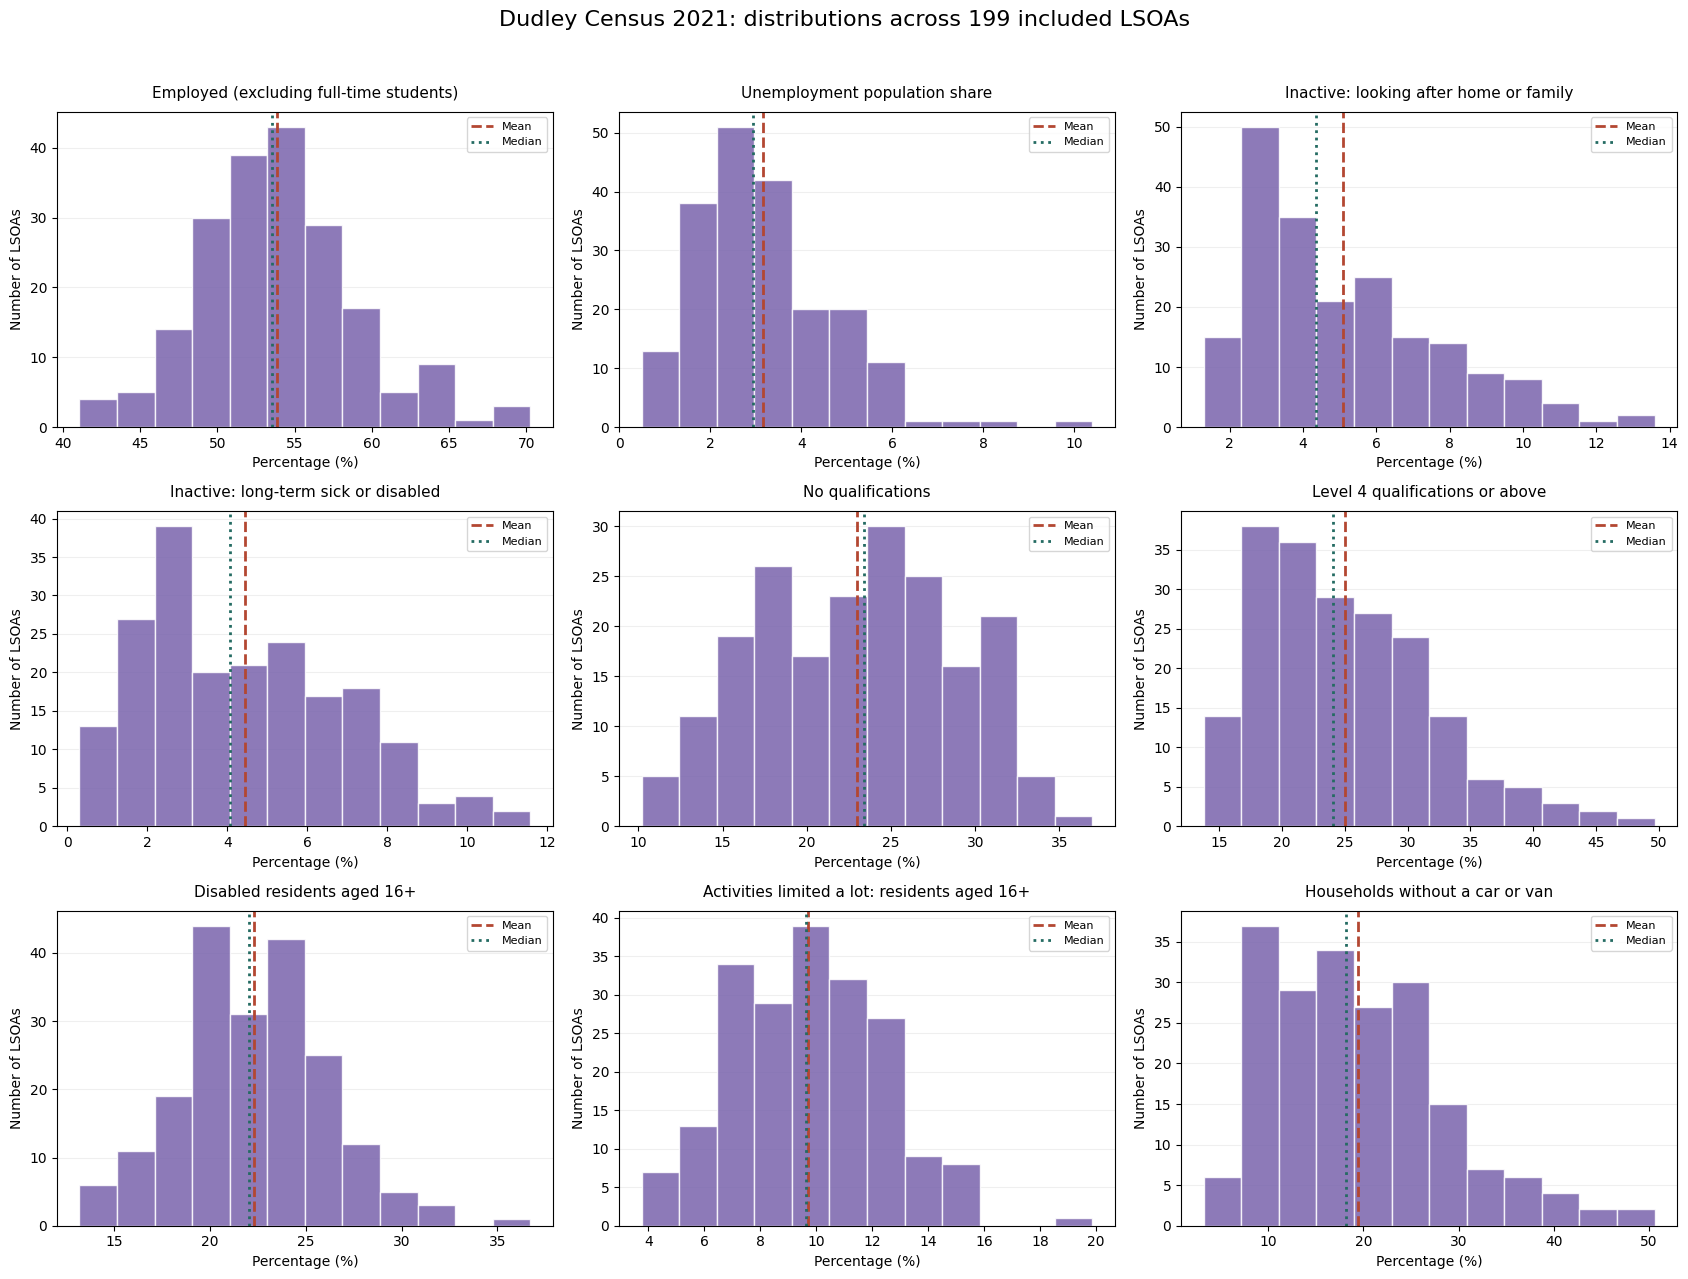

In [10]:
# Developed with ChatGPT assistance to visualise Census distributions.

%matplotlib inline
import matplotlib.pyplot as plt

# Readable labels in the same order as census_measures.
measure_labels = [
    "Employed (excluding full-time students)",
    "Unemployment population share",
    "Inactive: looking after home or family",
    "Inactive: long-term sick or disabled",
    "No qualifications",
    "Level 4 qualifications or above",
    "Disabled residents aged 16+",
    "Activities limited a lot: residents aged 16+",
    "Households without a car or van"
]

fig, axes = plt.subplots(3, 3, figsize=(17, 13))

for ax, column, label in zip(
    axes.flat, census_measures, measure_labels
):
    values = df[column]

    ax.hist(
        values,
        bins=12,
        color="#7963AC",
        edgecolor="white",
        alpha=0.85
    )
    ax.axvline(
        values.mean(),
        color="#B34732",
        linestyle="--",
        linewidth=2,
        label="Mean"
    )
    ax.axvline(
        values.median(),
        color="#246B62",
        linestyle=":",
        linewidth=2,
        label="Median"
    )

    ax.set_title(label, fontsize=11, pad=10)
    ax.set_xlabel("Percentage (%)")
    ax.set_ylabel("Number of LSOAs")
    ax.legend(fontsize=8)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

fig.suptitle(
    "Dudley Census 2021: distributions across 199 included LSOAs",
    fontsize=16
)
plt.tight_layout(rect=[0, 0, 1, 0.96])
from pathlib import Path

# Save the figure in a separate visualisations folder.
Path("visualisations").mkdir(exist_ok=True)

fig.savefig(
    "visualisations/census_measure_distributions.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Findings

Employment percentages are concentrated around the low-to-mid 50s,
with the mean and median close together.

Unemployment population share, inactivity due to home or family
responsibilities, and inactivity due to long-term sickness or disability
show right-tailed distributions. Most neighbourhoods have lower values,
while a smaller number have considerably higher shares.

Level 4 or above qualifications and households without a car or van
also show right tails, with their means above their medians.

The no-qualifications distribution is broadly spread, with less obvious
asymmetry. Disability and activities-limited-a-lot percentages are more
centrally concentrated, although a few areas have higher values.

Potentially unusual values include unemployment population shares
above 8%, households without a car or van approaching 50%, and
disability shares above 35%. These warrant closer inspection but
are not automatically errors.

Histogram shapes depend partly on the chosen bins. These are visual
observations, not formal tests of normality or evidence of causation.

---

## 6. Flag unusual Census values for investigation

Use the interquartile range (IQR) to flag unusually low or high values
for each selected Census measure.

The IQR is the difference between the first and third quartiles.
Values below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR are flagged.

This is an exploratory rule, not a test for data errors. Skewed
distributions can contain valid observations outside these limits.

Report the limits and number of flagged areas for each measure,
then identify the affected LSOAs. An area may be flagged for more
than one measure.

Retain all observations while investigating their context.

In [11]:
# Developed with ChatGPT assistance to flag unusual Census values.

iqr_results = []
flagged_tables = []

for column in census_measures:
    values = df[column]

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr

    below = values < lower_limit
    above = values > upper_limit
    flagged = below | above

    iqr_results.append({
        "Measure": column,
        "Lower_Limit": lower_limit,
        "Upper_Limit": upper_limit,
        "Below": int(below.sum()),
        "Above": int(above.sum()),
        "Total_Flagged": int(flagged.sum())
    })

    area_details = df.loc[
        flagged, ["LSOA_Code", "LSOA_Name"]
    ].copy()
    area_details["Measure"] = column
    area_details["Value_Pct"] = values.loc[flagged]
    area_details["Direction"] = [
        "Below" if value < lower_limit else "Above"
        for value in values.loc[flagged]
    ]

    flagged_tables.append(area_details)

iqr_summary = pd.DataFrame(iqr_results)
flagged_values = pd.concat(flagged_tables, ignore_index=True)

print("IQR screening summary:")
print(iqr_summary.round(2).to_string(index=False))

print("\nFlagged area-measure observations:")
print(flagged_values.round(2).to_string(index=False))

print(
    "\nUnique LSOAs flagged:",
    flagged_values["LSOA_Code"].nunique()
)
print(f"Rows retained in the dataset: {len(df)}")

IQR screening summary:
                                Measure  Lower_Limit  Upper_Limit  Below  Above  Total_Flagged
          Employed_Excl_FT_Students_Pct        41.11        66.24      1      4              5
        Unemployed_Excl_FT_Students_Pct        -0.76         6.76      0      3              3
            Inactive_Home_Or_Family_Pct        -2.64        12.37      0      2              2
Inactive_Long_Term_Sick_Or_Disabled_Pct        -3.26        11.88      0      0              0
                  No_Qualifications_Pct         4.69        40.99      0      0              0
                  Level_4_And_Above_Pct         5.29        43.61      0      3              3
                   Disabled_16_Plus_Pct        12.09        32.56      0      1              1
              Limited_A_Lot_16_Plus_Pct         1.98        17.27      0      1              1
              No_Car_Van_Households_Pct        -7.37        44.54      0      3              3

Flagged area-measure obser

### Findings

The IQR screening flagged 18 area-measure observations across
13 unique LSOAs. All 199 areas remain in the dataset.

- Employment flagged five areas: four above the upper limit and
  one below the lower limit. Dudley 013E was only slightly below
  the lower threshold, at 41.07% compared with 41.11%.
- Three areas had high unemployment population shares: Dudley 022A,
  Dudley 037B and Dudley 039B. These same areas also had high
  percentages of households without a car or van.
- Dudley 013E was flagged for a high disability share (36.73%) and
  a high share whose activities are limited a lot (19.88%).
  These measures overlap because the latter is a disability subgroup.
- Two areas were flagged for high inactivity due to home or family
  responsibilities, and three for high Level 4 or above qualifications.
- No values were flagged for no qualifications or inactivity due
  to long-term sickness or disability.

The overlap between high unemployment population shares and households
without a car warrants further exploration. It does not establish that
the same individuals experience both circumstances or that one causes
the other.

Negative lower IQR limits are mathematical thresholds, not observed
negative percentages. Being flagged does not establish a data error,
and not being flagged does not guarantee that a value is correct.

The flagged areas will be examined using their underlying counts and
denominators before drawing further conclusions. No values were removed.

---

## 7. Inspect counts and denominators for flagged values

Examine the underlying counts and source-specific denominators for
the observations flagged by the IQR screening.

Recalculate each flagged percentage as its count divided by its
denominator, multiplied by 100. Compare the result with the stored
percentage and check that the denominator is positive and the count
falls between zero and its total.

This checks arithmetic consistency within the prepared dataset.
It is not an independent comparison with the original source files.

Retain all areas. An unusual percentage may reflect a real local
pattern, and these checks alone cannot explain its cause.

In [12]:
# Developed with ChatGPT assistance to inspect flagged percentages.

# Match each percentage to its count and source-specific denominator.
measure_sources = {
    "Employed_Excl_FT_Students_Pct": (
        "Employed_Excl_FT_Students", "Economic_Total_16_Plus"
    ),
    "Unemployed_Excl_FT_Students_Pct": (
        "Unemployed_Excl_FT_Students", "Economic_Total_16_Plus"
    ),
    "Inactive_Home_Or_Family_Pct": (
        "Inactive_Home_Or_Family", "Economic_Total_16_Plus"
    ),
    "Inactive_Long_Term_Sick_Or_Disabled_Pct": (
        "Inactive_Long_Term_Sick_Or_Disabled", "Economic_Total_16_Plus"
    ),
    "No_Qualifications_Pct": (
        "No_Qualifications", "Qualifications_Total_16_Plus"
    ),
    "Level_4_And_Above_Pct": (
        "Level_4_And_Above", "Qualifications_Total_16_Plus"
    ),
    "Disabled_16_Plus_Pct": (
        "Disabled_16_Plus", "Disability_Total_16_Plus"
    ),
    "Limited_A_Lot_16_Plus_Pct": (
        "Limited_A_Lot_16_Plus", "Disability_Total_16_Plus"
    ),
    "No_Car_Van_Households_Pct": (
        "No_Car_Van_Households", "Total_Households"
    )
}

# Use LSOA codes to look up each area's counts and totals.
# Reference:
# https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.set_index.html
area_lookup = df.set_index("LSOA_Code")
inspection_rows = []

# Iterate through the flagged area-measure observations.
# Reference:
# https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.iterrows.html
for _, flagged_row in flagged_values.iterrows():
    measure = flagged_row["Measure"]
    count_column, total_column = measure_sources[measure]

    # Select the area by its LSOA code.
    
    area = area_lookup.loc[flagged_row["LSOA_Code"]]

    count = area[count_column]
    total = area[total_column]
    stored_pct = area[measure]

    # Recalculate the percentage, avoiding division by zero.
    recalculated_pct = (
        count / total * 100 if total > 0 else float("nan")
    )
    difference = abs(stored_pct - recalculated_pct)

    # Check count validity and agreement within a small numeric tolerance.
    inspection_rows.append({
        "LSOA_Code": flagged_row["LSOA_Code"],
        "LSOA_Name": flagged_row["LSOA_Name"],
        "Measure": measure,
        "Count": count,
        "Denominator": total_column,
        "Total": total,
        "Stored_Pct": stored_pct,
        "Recalculated_Pct": recalculated_pct,
        "Valid_Count_And_Total": bool(
            total > 0 and 0 <= count <= total
        ),
        "Calculation_Matches": bool(difference < 0.000001)
    })

# Convert the inspection records into a table.
# Reference:
# https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.html
flagged_inspection = pd.DataFrame(inspection_rows)

# Round only the displayed results and print all columns.
print(flagged_inspection.round(4).to_string(index=False))

# Summarise failed checks without changing or removing any rows.
print(
    "\nInvalid counts or denominators:",
    (~flagged_inspection["Valid_Count_And_Total"]).sum()
)
print(
    "Percentage calculation mismatches:",
    (~flagged_inspection["Calculation_Matches"]).sum()
)
print(f"Rows retained: {len(df)}")

LSOA_Code   LSOA_Name                         Measure  Count                  Denominator  Total  Stored_Pct  Recalculated_Pct  Valid_Count_And_Total  Calculation_Matches
E01009780 Dudley 009A   Employed_Excl_FT_Students_Pct   1238       Economic_Total_16_Plus   1762     70.2611           70.2611                   True                 True
E01009784 Dudley 009B   Employed_Excl_FT_Students_Pct    872       Economic_Total_16_Plus   1286     67.8072           67.8072                   True                 True
E01009886 Dudley 013E   Employed_Excl_FT_Students_Pct    667       Economic_Total_16_Plus   1624     41.0714           41.0714                   True                 True
E01009731 Dudley 023A   Employed_Excl_FT_Students_Pct    899       Economic_Total_16_Plus   1320     68.1061           68.1061                   True                 True
E01009730 Dudley 028D   Employed_Excl_FT_Students_Pct    864       Economic_Total_16_Plus   1254     68.8995           68.8995                   

### Findings

All 18 flagged area-measure observations have positive denominators
and counts between zero and their respective totals. Every recalculated
percentage matches its stored value within the specified tolerance.

The flagged values are therefore internally consistent with the
counts and denominators in the prepared dataset. These checks do
not independently verify the original source data or explain why
the areas have unusual values.

For example:
- Dudley 022A has 173 unemployed residents excluding full-time students
  out of 1,664 residents aged 16 and over, giving a population share
  of 10.40%.
- Dudley 039B has 481 households without a car or van out of 951
  households, giving 50.58%.
- Dudley 013E has 595 disabled residents out of a disability-source
  total of 1,620 residents aged 16 and over, giving 36.73%.

Dudley 013E has different totals in the economic activity and
disability sources: 1,624 and 1,620 respectively. Each percentage
uses its own source-specific denominator. This check does not
establish the reason for that difference.

No arithmetic or count-range problems were detected among the
flagged observations. All 199 LSOAs are retained for further analysis.

---

## 8. Compare profiles of flagged neighbourhoods

Use a heatmap to compare the 13 flagged LSOAs across the nine selected
Census measures.

Each value shows the difference between an area's percentage and the
median percentage across all 199 included LSOAs, in percentage points.

Positive values indicate a share above the median; negative values
indicate a share below it. The same colour scale is used throughout.

These differences describe area profiles, not an overall disadvantage
score. A higher value has a different meaning for each measure.
Disability measures overlap, and household percentages describe a
different population from resident percentages.

The areas were selected because at least one measure was flagged.
Patterns in this subset should not be generalised to all Dudley areas.

Save the chart in the visualisations folder.

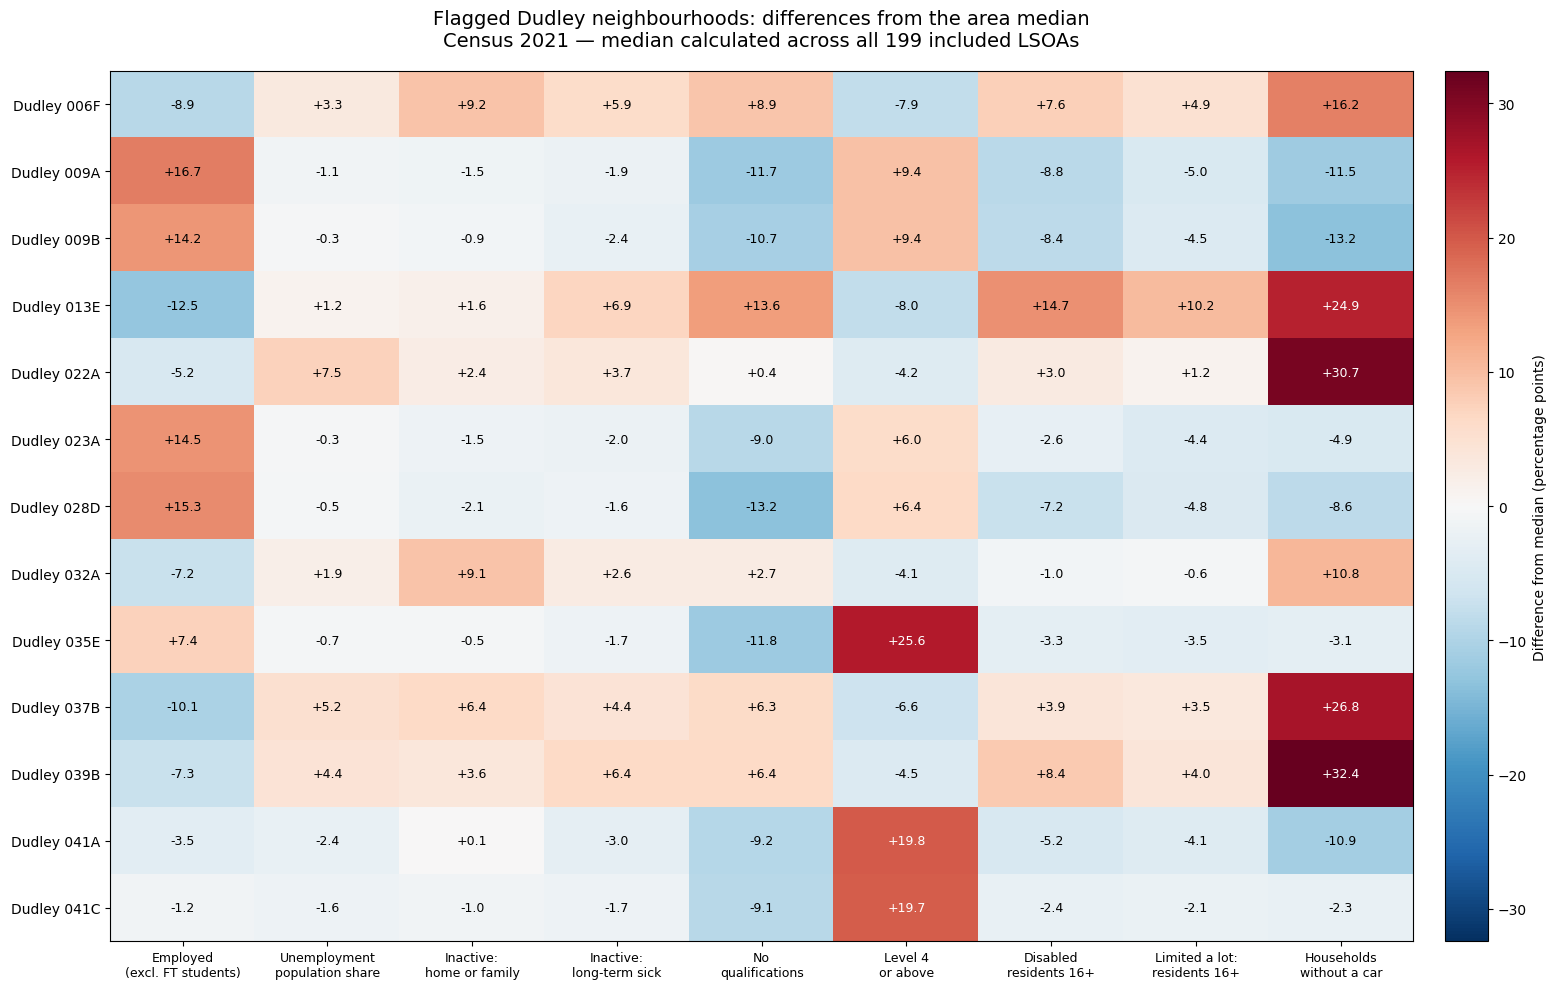

Saved: visualisations/flagged_area_profiles.png


In [13]:
%matplotlib inline

# Developed with ChatGPT assistance to compare flagged area profiles.

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Select the flagged areas once each and sort them by name.
flagged_codes = flagged_values["LSOA_Code"].unique()

flagged_profiles = (
    df.loc[df["LSOA_Code"].isin(flagged_codes)]
    .sort_values("LSOA_Name")
    .set_index("LSOA_Name")[census_measures]
)

# Subtract each measure's median across all 199 areas.
# Axis alignment matches each median to the correct column.
# Reference:
# https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.sub.html
median_differences = flagged_profiles.sub(
    df[census_measures].median(),
    axis="columns"
)

chart_labels = [
    "Employed\n(excl. FT students)",
    "Unemployment\npopulation share",
    "Inactive:\nhome or family",
    "Inactive:\nlong-term sick",
    "No\nqualifications",
    "Level 4\nor above",
    "Disabled\nresidents 16+",
    "Limited a lot:\nresidents 16+",
    "Households\nwithout a car"
]

# Centre the colour scale on zero with equal positive/negative limits.
colour_limit = float(np.abs(median_differences.to_numpy()).max())

fig, ax = plt.subplots(figsize=(17, 10))

# Render the matrix using one shared colour scale.
# Reference:
# https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.imshow.html
heatmap = ax.imshow(
    median_differences.to_numpy(),
    cmap="RdBu_r",
    vmin=-colour_limit,
    vmax=colour_limit,
    aspect="auto"
)

ax.set_xticks(range(len(chart_labels)))
ax.set_xticklabels(chart_labels, fontsize=9)
ax.set_yticks(range(len(median_differences)))
ax.set_yticklabels(median_differences.index, fontsize=10)

# Annotate each cell with its percentage-point difference.
for row in range(median_differences.shape[0]):
    for column in range(median_differences.shape[1]):
        value = median_differences.iloc[row, column]
        text_colour = (
            "white" if abs(value) > colour_limit * 0.55 else "black"
        )
        ax.text(
            column,
            row,
            f"{value:+.1f}",
            ha="center",
            va="center",
            color=text_colour,
            fontsize=9
        )

ax.set_title(
    "Flagged Dudley neighbourhoods: differences from the area median\n"
    "Census 2021 — median calculated across all 199 included LSOAs",
    fontsize=14,
    pad=18
)

colour_bar = fig.colorbar(heatmap, ax=ax, pad=0.02)
colour_bar.set_label("Difference from median (percentage points)")

fig.tight_layout()

Path("visualisations").mkdir(exist_ok=True)
figure_path = "visualisations/flagged_area_profiles.png"
fig.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()
print(f"Saved: {figure_path}")

### Findings

The flagged neighbourhoods show different combinations of characteristics.
All differences below are percentage points relative to the median
across the 199 included LSOAs.

- Dudley 022A, 037B and 039B have above-median unemployment population
  shares and households without a car. Their no-car shares are
  30.7, 26.8 and 32.4 percentage points above the median respectively.
  Employment shares are below the median in all three areas.
- Dudley 013E combines lower employment (-12.5 points) with higher
  disability (+14.7), no qualifications (+13.6) and households
  without a car (+24.9).
- Dudley 006F and 032A both have high home or family inactivity
  (+9.2 and +9.1 points), but their disability profiles differ:
  +7.6 points in 006F compared with -1.0 in 032A.
- Dudley 009A, 009B, 023A and 028D have higher employment shares,
  lower no-qualification shares and higher Level 4 or above shares
  than the respective medians.
- Dudley 035E has a particularly high Level 4 or above share
  (+25.6 points). However, higher qualifications do not always
  coincide with above-median employment: Dudley 041A and 041C have
  high Level 4 shares but slightly below-median employment shares.

These contrasting profiles suggest that further exploration should
consider combinations of characteristics rather than a single measure.

The heatmap does not identify individual support needs or establish
causal relationships. Age composition and other unmeasured factors
may contribute to the patterns. Findings from these deliberately
selected areas cannot be generalised to all neighbourhoods.

Colours indicate direction and size of differences, not whether
an area is better or worse overall.

---

# Section 1

Section 1 content

---

# Section 2

Section 2 content

---

NOTE

* You may add as many sections as you want, as long as it supports your project workflow.
* All notebook's cells should be run top-down (you can't create a dynamic wherein a given point you need to go back to a previous cell to execute some task, like go back to a previous cell and refresh a variable content)

---

# Push files to Repo

* In cases where you don't need to push files to Repo, you may replace this section with "Conclusions and Next Steps" and state your conclusions and next steps.

In [ ]:
import os
try:
  # create your folder here
  # os.makedirs(name='')
except Exception as e:
  print(e)
